# Results processing

Load, summarise, compare, and visualise benchmark results.

In [22]:
from __future__ import annotations

import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "06_NOTEBOOKS" else Path.cwd()
MODULES_DIR = REPO_ROOT / "modules"
if str(MODULES_DIR) not in sys.path:
    sys.path.insert(0, str(MODULES_DIR))

from load_results import load_results, save_cache
from xgb_prediction_plots import plot_parity_grid, plot_residual_grid

In [23]:
DATE = "20260923"
OUTPUTS_ROOT = REPO_ROOT / "07_OUTPUTS"
RUN_DIR = OUTPUTS_ROOT / DATE
FIGURES_DIR = RUN_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

EMBEDDING_LABELS = {
    "morgan_fps": "ECFP4",
    "hq_descriptor": "QU",
    "chemeleon": "CheMeleon",
    "molclr": "MolCLR",
    "maceoff_large": "MACE-OFF",
}
MODEL_LABELS = {"linear": "LR", "rf": "RF", "xgboost": "XGB", "mlp": "MLP"}
DATASET_LABELS = {"CD": r"$\rho_{cryst}$"}

EMBEDDING_ORDER = ["ECFP4", "QU", "CheMeleon", "MolCLR", "MACE-OFF"]
MODEL_ORDER = ["LR", "RF", "XGB", "MLP"]
DATASET_ORDER = [r"$\rho_{cryst}$", "HOF", "IS"]
DATASET_UNITS = {
    r"$\rho_{cryst}$": r"Test RMSE (g/cm$^3$)",
    "HOF": "Test RMSE (kJ/mol)",
    "IS": "Test RMSE (log(J))",
}
ALPHA = 0.05

## Load and prepare results

In [24]:
results_df = load_results(OUTPUTS_ROOT, date=DATE)
save_cache(results_df, outputs_root=OUTPUTS_ROOT, date=DATE)
results_df.head()

,date,dataset_from_path,model_from_path,embedding_from_path,split_dir,summary_path,split_method_from_path,split_seed_from_path,dataset,model,...,test_f1_macro,test_f1_weighted,test_confusion_matrix,test_classification_report,test_roc_auc_ovr_macro,train_roc_auc_error,test_roc_auc_error,train_roc_auc,test_roc_auc,run_id
0,20260923,HOF,linear,molclr,split=random_seed2_modelseed=3,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20260923|HOF|linear|molclr|random_seed2|42.0|s...
1,20260923,HOF,linear,molclr,split=cluster_label2_modelseed=2,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20260923|HOF|linear|molclr|cluster_label2|42.0...
2,20260923,HOF,linear,molclr,split=random_seed3_modelseed=4,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20260923|HOF|linear|molclr|random_seed3|42.0|s...
3,20260923,HOF,linear,molclr,split=cluster_label2_modelseed=3,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20260923|HOF|linear|molclr|cluster_label2|42.0...
4,20260923,HOF,linear,molclr,split=random_seed0_modelseed=3,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20260923|HOF|linear|molclr|random_seed0|42.0|s...


In [25]:
def prepare_results(results: pd.DataFrame) -> pd.DataFrame:
    """Apply display labels, ordering, and the agreed quality filter."""
    prepared = results.loc[results["test_R2"] > -0.5].copy()
    prepared["embedding"] = prepared["embedding"].replace(EMBEDDING_LABELS)
    prepared["model"] = prepared["model"].replace(MODEL_LABELS)
    prepared["dataset"] = prepared["dataset"].replace(DATASET_LABELS)

    prepared["embedding"] = pd.Categorical(
        prepared["embedding"], categories=EMBEDDING_ORDER, ordered=True
    )
    prepared["model"] = pd.Categorical(
        prepared["model"], categories=MODEL_ORDER, ordered=True
    )
    prepared["dataset"] = pd.Categorical(
        prepared["dataset"], categories=DATASET_ORDER, ordered=True
    )
    return prepared


df = prepare_results(results_df)
result_columns = [
    "dataset", "model", "seed", "split_method", "embedding",
    "test_MAE", "test_RMSE", "test_R2",
]
clean_results = df[result_columns].dropna(subset=["dataset", "model", "embedding"])
clean_results.head()

,dataset,model,seed,split_method,embedding,test_MAE,test_RMSE,test_R2
0,HOF,LR,3,random_seed2,MolCLR,43.560634,59.489496,0.664432
1,HOF,LR,2,cluster_label2,MolCLR,56.054178,84.211733,0.303912
2,HOF,LR,4,random_seed3,MolCLR,35.439774,51.156573,0.742318
3,HOF,LR,3,cluster_label2,MolCLR,55.767242,80.304795,0.367003
4,HOF,LR,3,random_seed0,MolCLR,49.183236,73.007756,0.615135


## Reusable analysis and plotting helpers

In [26]:
def save_figure(fig: plt.Figure, filename: str) -> Path:
    """Save a figure consistently, then display it in the notebook."""
    path = FIGURES_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved {path.relative_to(REPO_ROOT)}")
    return path


def select_split(results: pd.DataFrame, split_name: str) -> pd.DataFrame:
    mask = results["split_method"].str.contains(split_name, case=False, na=False)
    return results.loc[mask].copy()


def summarise_results(results: pd.DataFrame) -> pd.DataFrame:
    return (
        results.groupby(["dataset", "embedding"], observed=True)
        [["test_RMSE", "test_R2"]]
        .agg(["mean", "std"])
        .round(3)
    )

In [27]:
def plot_benchmark_rmse(results: pd.DataFrame, filename: str) -> plt.Figure:
    """Plot test RMSE by prediction head and embedding for each dataset."""
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    palette = sns.color_palette("tab10", n_colors=len(EMBEDDING_ORDER))
    fig, axes = plt.subplots(len(DATASET_ORDER), 1, figsize=(14, 14), dpi=300)

    pretrained = {"CheMeleon", "MolCLR", "MACE-OFF"}
    first_pretrained = min(EMBEDDING_ORDER.index(name) for name in pretrained)
    last_pretrained = max(EMBEDDING_ORDER.index(name) for name in pretrained)
    group_width = 0.8
    bar_width = group_width / len(EMBEDDING_ORDER)
    legend_handles = legend_labels = None

    for ax, dataset in zip(axes, DATASET_ORDER):
        subset = results.loc[results["dataset"] == dataset]
        sns.barplot(
            data=subset,
            x="model",
            y="test_RMSE",
            hue="embedding",
            hue_order=EMBEDDING_ORDER,
            palette=palette,
            errorbar="sd",
            gap=0.1,
            ax=ax,
        )

        for x_position in ax.get_xticks():
            left = x_position - group_width / 2 + first_pretrained * bar_width
            right = x_position - group_width / 2 + (last_pretrained + 1) * bar_width
            ax.axvspan(left, right, color="lightgray", alpha=0.2, zorder=0)

        for patch in ax.patches:
            patch.set_zorder(2)

        ax.set(title=str(dataset), xlabel="", ylabel=DATASET_UNITS[dataset])
        ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)
        sns.despine(ax=ax)

        if legend_handles is None:
            legend_handles, legend_labels = ax.get_legend_handles_labels()
        if ax.get_legend() is not None:
            ax.get_legend().remove()

    legend_handles.append(Patch(facecolor="lightgray", alpha=0.5))
    legend_labels.append("Pre-trained embeddings")
    fig.legend(
        legend_handles,
        legend_labels,
        title="Embedding",
        loc="center left",
        bbox_to_anchor=(0.84, 0.5),
        frameon=False,
    )
    fig.tight_layout(rect=[0, 0, 0.88, 1])
    save_figure(fig, filename)
    return fig

In [28]:
def aggregate_paired_runs(results: pd.DataFrame) -> pd.DataFrame:
    """Average over prediction heads while retaining paired experimental runs."""
    return (
        results.loc[results["embedding"].isin(EMBEDDING_ORDER)]
        .groupby(
            ["dataset", "embedding", "seed", "split_method"],
            as_index=False,
            observed=True,
        )["test_RMSE"]
        .mean()
    )


def compare_to_reference(
    results: pd.DataFrame,
    reference: str = "QU",
    candidates: tuple[str, ...] = ("ECFP4", "CheMeleon", "MolCLR", "MACE-OFF"),
) -> pd.DataFrame:
    """Test whether a reference embedding has lower RMSE than each candidate."""
    paired_runs = aggregate_paired_runs(results)
    records = []

    for dataset, dataset_scores in paired_runs.groupby("dataset", observed=True):
        reference_scores = (
            dataset_scores.loc[dataset_scores["embedding"] == reference,
                               ["split_method", "seed", "test_RMSE"]]
            .rename(columns={"test_RMSE": "reference_RMSE"})
        )
        for candidate in candidates:
            candidate_scores = (
                dataset_scores.loc[dataset_scores["embedding"] == candidate,
                                   ["split_method", "seed", "test_RMSE"]]
                .rename(columns={"test_RMSE": "candidate_RMSE"})
            )
            paired = reference_scores.merge(
                candidate_scores, on=["split_method", "seed"], how="inner"
            ).dropna()
            if len(paired) < 2:
                raise ValueError(f"Need at least two paired runs for {dataset=}, {candidate=}")

            test = ttest_rel(
                paired["reference_RMSE"], paired["candidate_RMSE"], alternative="less"
            )
            records.append({
                "Dataset": dataset,
                "Reference": reference,
                "Candidate": candidate,
                "Paired runs": len(paired),
                "Reference mean RMSE": paired["reference_RMSE"].mean(),
                "Candidate mean RMSE": paired["candidate_RMSE"].mean(),
                "t statistic": test.statistic,
                "p value": test.pvalue,
                "Result": (
                    "Reference significantly better"
                    if test.pvalue < ALPHA
                    else "Candidate equal or better"
                ),
            })

    return pd.DataFrame(records).set_index(["Dataset", "Reference", "Candidate"])

In [29]:
def compare_to_best(results: pd.DataFrame) -> pd.DataFrame:
    """Compare every embedding with the lowest-mean embedding per dataset."""
    paired_runs = aggregate_paired_runs(results)
    records = []

    for dataset, dataset_scores in paired_runs.groupby("dataset", observed=True):
        means = dataset_scores.groupby("embedding", observed=True)["test_RMSE"].mean().sort_values()
        best_embedding = means.index[0]
        best_scores = (
            dataset_scores.loc[dataset_scores["embedding"] == best_embedding,
                               ["split_method", "seed", "test_RMSE"]]
            .rename(columns={"test_RMSE": "best_RMSE"})
        )
        dataset_records = []

        for embedding in means.index[1:]:
            other_scores = (
                dataset_scores.loc[dataset_scores["embedding"] == embedding,
                                   ["split_method", "seed", "test_RMSE"]]
                .rename(columns={"test_RMSE": "other_RMSE"})
            )
            paired = best_scores.merge(
                other_scores, on=["split_method", "seed"], how="inner"
            ).dropna()
            if len(paired) < 2:
                raise ValueError(f"Need at least two paired runs for {dataset=}, {embedding=}")

            test = ttest_rel(paired["best_RMSE"], paired["other_RMSE"], alternative="less")
            dataset_records.append({
                "Dataset": dataset,
                "Best embedding": best_embedding,
                "Compared embedding": embedding,
                "Paired runs": len(paired),
                "Best mean RMSE": paired["best_RMSE"].mean(),
                "Other mean RMSE": paired["other_RMSE"].mean(),
                "RMSE difference": (paired["other_RMSE"] - paired["best_RMSE"]).mean(),
                "t statistic": test.statistic,
                "Raw p value": test.pvalue,
            })

        if dataset_records:
            reject, adjusted_p, _, _ = multipletests(
                [record["Raw p value"] for record in dataset_records],
                alpha=ALPHA,
                method="holm",
            )
            for record, is_worse, p_value in zip(dataset_records, reject, adjusted_p):
                record["Holm-adjusted p value"] = p_value
                record["Result"] = (
                    "Significantly worse than best"
                    if is_worse
                    else "Not significantly worse than best"
                )
            records.extend(dataset_records)

    return pd.DataFrame(records).set_index(
        ["Dataset", "Best embedding", "Compared embedding"]
    )

In [30]:
def rank_embeddings(results: pd.DataFrame) -> pd.DataFrame:
    """Count dataset/model wins and calculate mean embedding rank."""
    seed_means = (
        results.groupby(["dataset", "model", "embedding"], as_index=False, observed=True)
        ["test_RMSE"]
        .mean()
    )
    seed_means["rank"] = seed_means.groupby(["dataset", "model"], observed=True)[
        "test_RMSE"
    ].rank(method="average", ascending=True)
    seed_means["win"] = seed_means["rank"].eq(1)

    return (
        seed_means.groupby("embedding", observed=True)
        .agg(**{"Win Count": ("win", "sum"), "Avg Rank": ("rank", "mean")})
        .sort_values(["Win Count", "Avg Rank"], ascending=[False, True])
        .round(2)
    )

## Random splits

test_RMSE         test_R2       
                              mean     std    mean    std
dataset        embedding                                 
$\rho_{cryst}$ ECFP4         0.132   0.023   0.338  0.121
               QU            0.120   0.027   0.460  0.128
               CheMeleon     0.124   0.029   0.425  0.173
               MolCLR        0.123   0.028   0.438  0.134
               MACE-OFF      0.112   0.031   0.535  0.155
HOF            ECFP4        62.792  10.711   0.602  0.095
               QU           53.069  11.429   0.708  0.110
               CheMeleon    54.672  12.542   0.692  0.123
               MolCLR       59.374  11.244   0.638  0.127
               MACE-OFF     52.655  11.141   0.721  0.079
IS             ECFP4         0.952   0.081   0.317  0.115
               QU            0.920   0.063   0.364  0.087
               CheMeleon     0.852   0.073   0.454  0.094
               MolCLR        0.845   0.071   0.461  0.097
               MACE-OFF      0.835   0.113   0.468  0.156

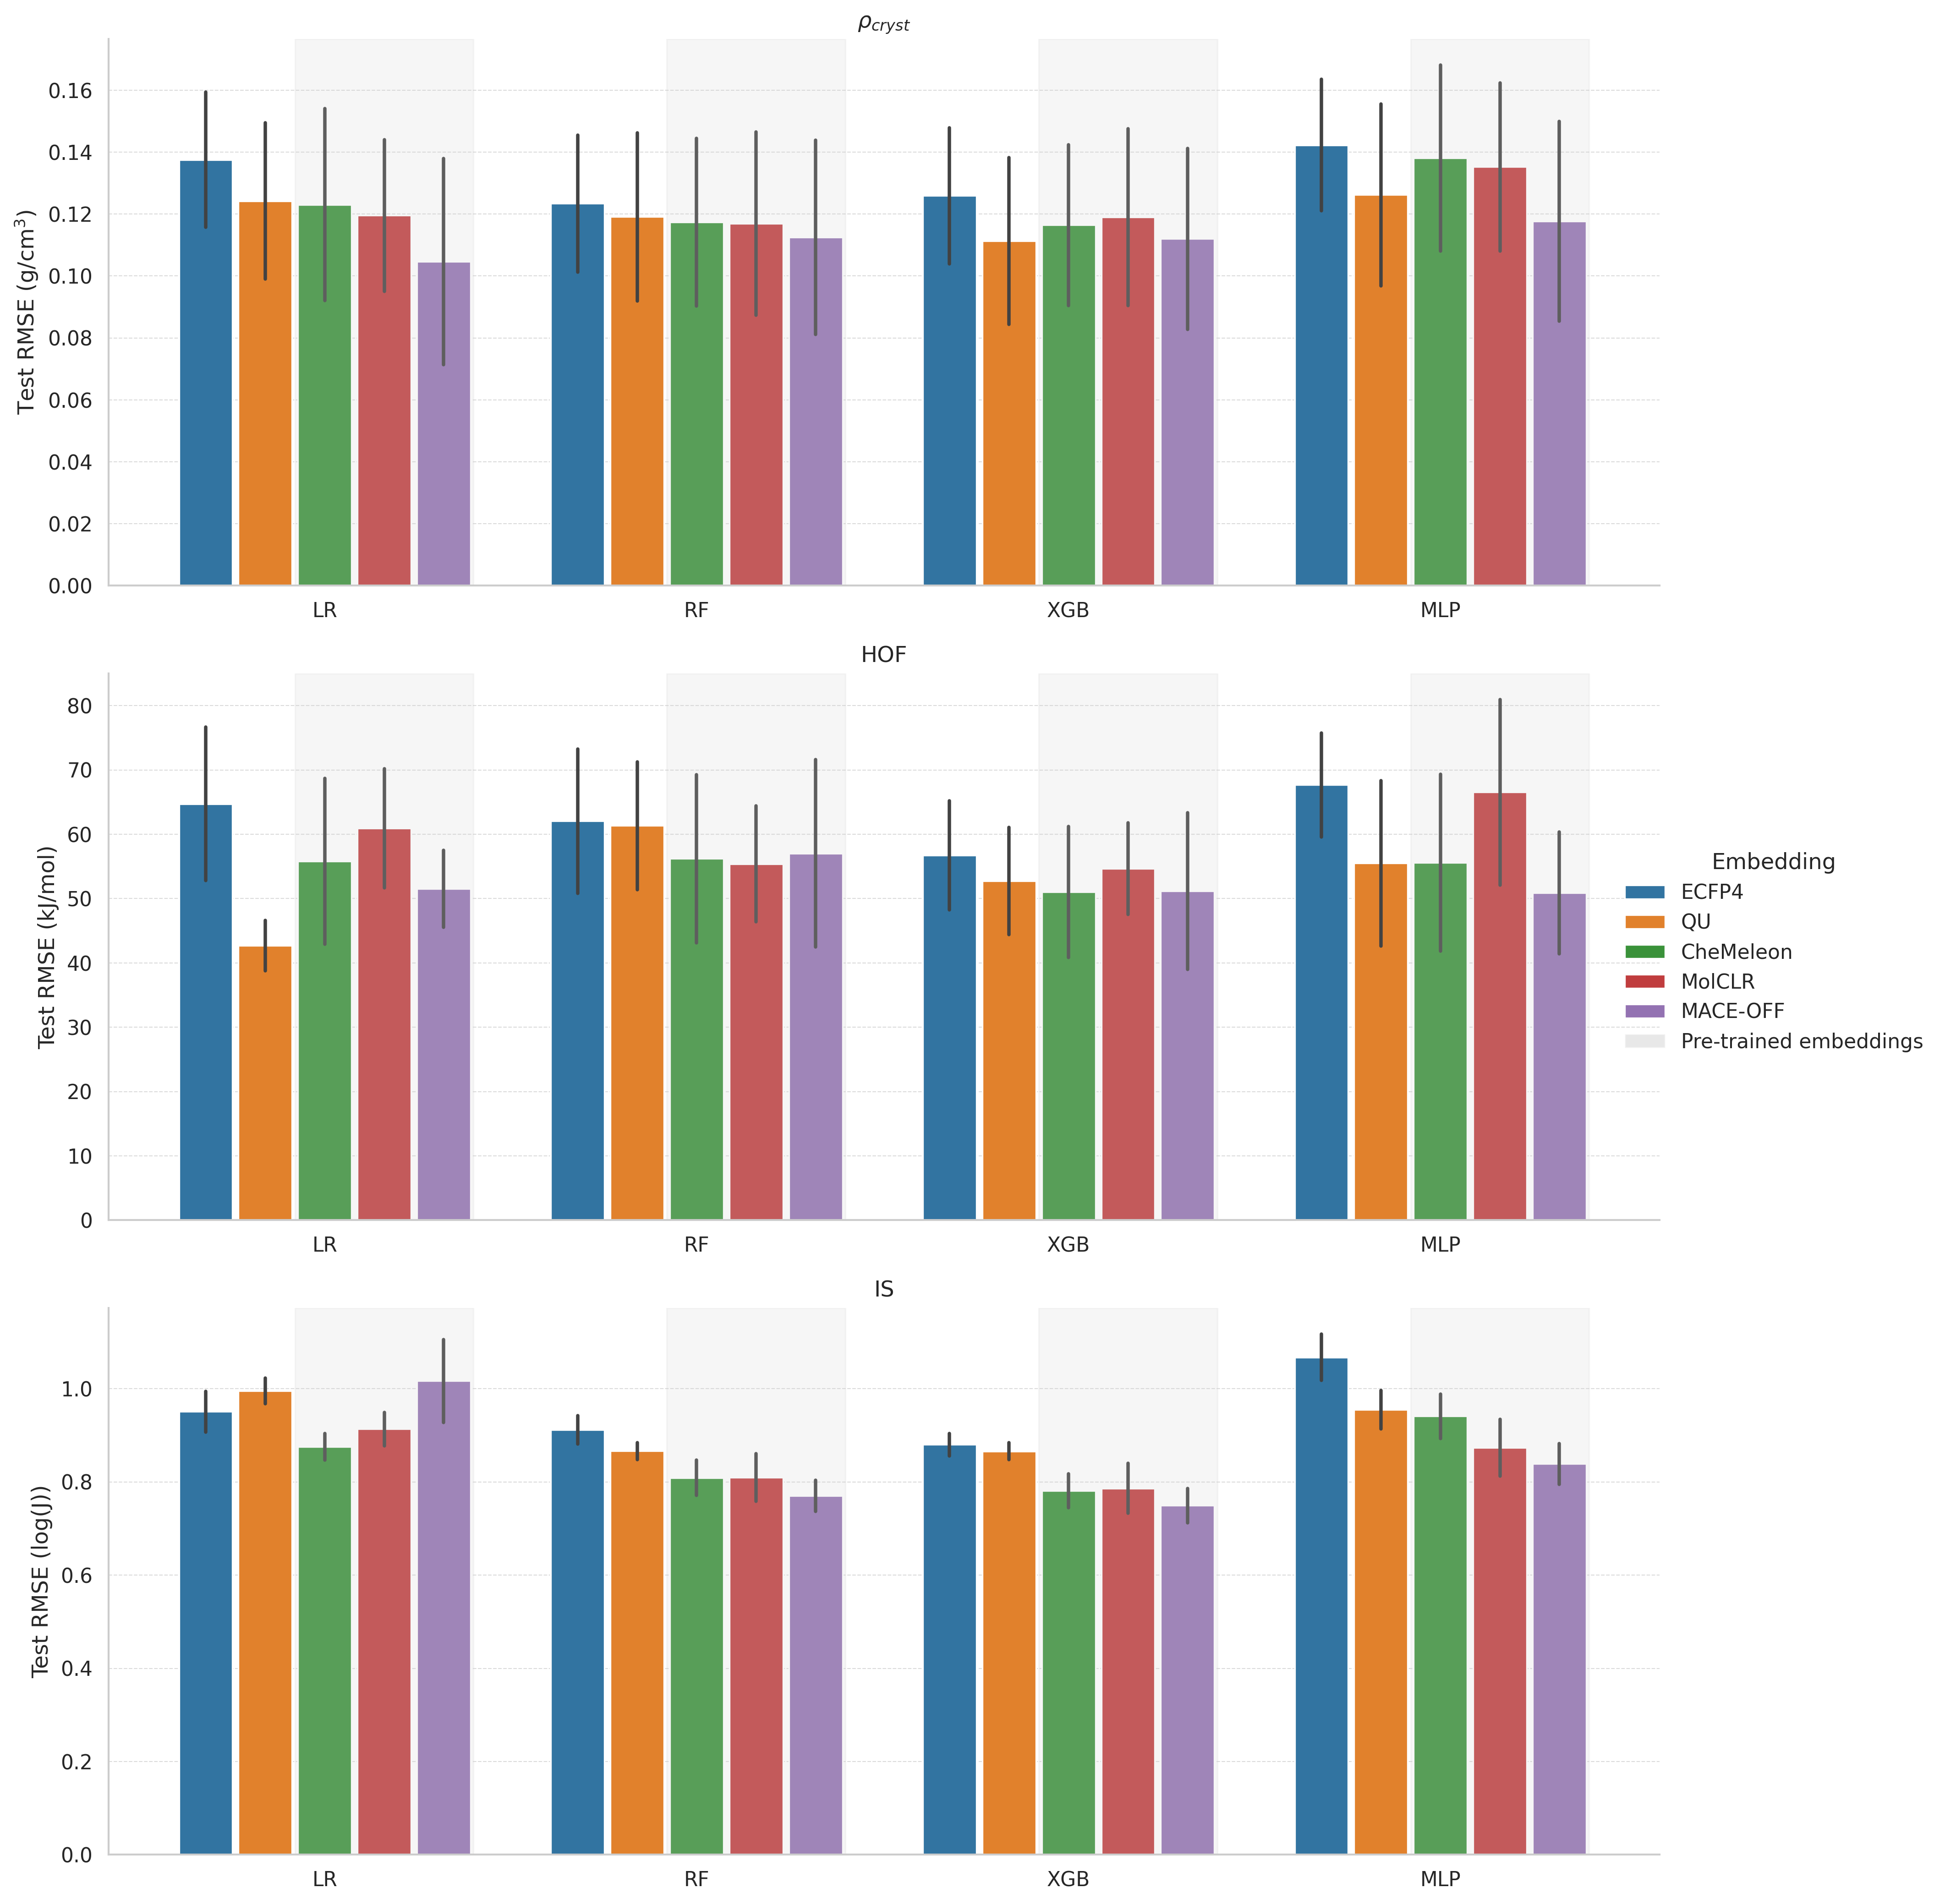

Saved 07_OUTPUTS/20260923/figures/random_split_benchmark_rmse.png


In [31]:
random_results = select_split(clean_results, "random")
display(summarise_results(random_results))
plot_benchmark_rmse(random_results, "random_split_benchmark_rmse.png");

In [32]:
random_results.groupby(["dataset", "model", "embedding"])[["test_RMSE", "test_R2"]].agg(("mean", "std")).round(3)

/tmp/ipykernel_25192/321736336.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  random_results.groupby(["dataset", "model", "embedding"])[["test_RMSE", "test_R2"]].agg(("mean", "std")).round(3)


test_RMSE         test_R2       
                                    mean     std    mean    std
dataset        model embedding                                 
$\rho_{cryst}$ LR    ECFP4         0.138   0.022   0.290  0.053
                     QU            0.124   0.025   0.424  0.095
                     CheMeleon     0.123   0.031   0.435  0.170
                     MolCLR        0.120   0.024   0.466  0.091
                     MACE-OFF      0.105   0.033   0.593  0.161
               RF    ECFP4         0.123   0.022   0.430  0.064
                     QU            0.119   0.027   0.473  0.110
                     CheMeleon     0.117   0.027   0.490  0.102
                     MolCLR        0.117   0.030   0.495  0.126
                     MACE-OFF      0.113   0.031   0.531  0.147
               XGB   ECFP4         0.126   0.022   0.405  0.075
                     QU            0.111   0.027   0.537  0.118
                     CheMeleon     0.116   0.026   0.497  0.096
                     MolCLR        0.119   0.029   0.475  0.122
                     MACE-OFF      0.112   0.029   0.532  0.139
               MLP   ECFP4         0.142   0.021   0.227  0.137
                     QU            0.126   0.029   0.404  0.147
                     CheMeleon     0.138   0.030   0.277  0.205
                     MolCLR        0.135   0.027   0.317  0.120
                     MACE-OFF      0.118   0.032   0.485  0.162
HOF            LR    ECFP4        64.734  11.932   0.582  0.081
                     QU           42.674   3.906   0.810  0.052
                     CheMeleon    55.826  12.900   0.684  0.116
                     MolCLR       60.911   9.245   0.625  0.077
                     MACE-OFF     51.513   5.965   0.732  0.046
               RF    ECFP4        62.046  11.233   0.613  0.091
                     QU           61.350   9.933   0.626  0.054
                     CheMeleon    56.218  13.066   0.680  0.096
                     MolCLR       55.402   9.036   0.690  0.069
                     MACE-OFF     57.030  14.563   0.675  0.103
               XGB   ECFP4        56.725   8.463   0.673  0.079
                     QU           52.764   8.335   0.721  0.052
                     CheMeleon    51.029  10.205   0.737  0.069
                     MolCLR       54.637   7.116   0.697  0.063
                     MACE-OFF     51.179  12.154   0.737  0.079
               MLP   ECFP4        67.663   8.094   0.538  0.080
                     QU           55.489  12.855   0.674  0.149
                     CheMeleon    55.614  13.746   0.667  0.180
                     MolCLR       66.546  14.420   0.540  0.189
                     MACE-OFF     50.899   9.481   0.740  0.062
IS             LR    ECFP4         0.951   0.044   0.323  0.054
                     QU            0.995   0.028   0.259  0.043
                     CheMeleon     0.876   0.028   0.425  0.051
                     MolCLR        0.913   0.036   0.375  0.061
                     MACE-OFF      1.016   0.089   0.211  0.136
               RF    ECFP4         0.912   0.030   0.378  0.033
                     QU            0.866   0.018   0.439  0.018
                     CheMeleon     0.809   0.038   0.510  0.039
                     MolCLR        0.809   0.051   0.508  0.067
                     MACE-OFF      0.770   0.033   0.556  0.032
               XGB   ECFP4         0.880   0.024   0.420  0.038
                     QU            0.866   0.018   0.439  0.027
                     CheMeleon     0.781   0.036   0.543  0.044
                     MolCLR        0.786   0.053   0.534  0.074
                     MACE-OFF      0.749   0.037   0.580  0.035
               MLP   ECFP4         1.067   0.050   0.148  0.062
                     QU            0.955   0.041   0.318  0.053
                     CheMeleon     0.941   0.048   0.337  0.061
                     MolCLR        0.873   0.061   0.426  0.090
                     MACE-OFF      0.839   0.044   0.474  0.042

### Are the foundation-model embeddings equal to or better than QU?

One-sided paired t-tests use matched seed/split runs after averaging across prediction heads. Lower RMSE is better.

In [33]:
display(compare_to_reference(random_results).round(3))

Paired runs  Reference mean RMSE  \
Dataset        Reference Candidate                                     
$\rho_{cryst}$ QU        ECFP4               25                0.120   
                         CheMeleon           25                0.120   
                         MolCLR              25                0.120   
                         MACE-OFF            25                0.120   
HOF            QU        ECFP4               25               53.069   
                         CheMeleon           25               53.069   
                         MolCLR              25               53.069   
                         MACE-OFF            25               53.069   
IS             QU        ECFP4               25                0.920   
                         CheMeleon           25                0.920   
                         MolCLR              25                0.920   
                         MACE-OFF            25                0.920   

                                    Candidate mean RMSE  t statistic  p value  \
Dataset        Reference Candidate                                              
$\rho_{cryst}$ QU        ECFP4                    0.132       -7.424    0.000   
                         CheMeleon                0.124       -2.320    0.015   
                         MolCLR                   0.123       -3.488    0.001   
                         MACE-OFF                 0.112        8.214    1.000   
HOF            QU        ECFP4                   62.792       -9.782    0.000   
                         CheMeleon               54.672       -1.450    0.080   
                         MolCLR                  59.374       -6.525    0.000   
                         MACE-OFF                52.655        0.369    0.642   
IS             QU        ECFP4                    0.952       -5.282    0.000   
                         CheMeleon                0.852       13.696    1.000   
                         MolCLR                   0.845        6.671    1.000   
                         MACE-OFF                 0.834       14.777    1.000   

                                                            Result  
Dataset        Reference Candidate                                  
$\rho_{cryst}$ QU        ECFP4      Reference significantly better  
                         CheMeleon  Reference significantly better  
                         MolCLR     Reference significantly better  
                         MACE-OFF        Candidate equal or better  
HOF            QU        ECFP4      Reference significantly better  
                         CheMeleon       Candidate equal or better  
                         MolCLR     Reference significantly better  
                         MACE-OFF        Candidate equal or better  
IS             QU        ECFP4      Reference significantly better  
                         CheMeleon       Candidate equal or better  
                         MolCLR          Candidate equal or better  
                         MACE-OFF        Candidate equal or better

### Comparisons with the best embedding

Each embedding is compared with the lowest-mean embedding for its dataset. Holm correction is applied within each dataset.

In [34]:
display(compare_to_best(random_results).round(3))
display(rank_embeddings(random_results))

Paired runs  Best mean RMSE  \
Dataset        Best embedding Compared embedding                                
$\rho_{cryst}$ MACE-OFF       QU                           25           0.112   
                              MolCLR                       25           0.112   
                              CheMeleon                    25           0.112   
                              ECFP4                        25           0.112   
HOF            MACE-OFF       QU                           25          52.655   
                              CheMeleon                    25          52.655   
                              MolCLR                       25          52.655   
                              ECFP4                        25          52.655   
IS             MACE-OFF       MolCLR                       25           0.834   
                              CheMeleon                    25           0.834   
                              QU                           25           0.834   
                              ECFP4                        25           0.834   

                                                  Other mean RMSE  \
Dataset        Best embedding Compared embedding                    
$\rho_{cryst}$ MACE-OFF       QU                            0.120   
                              MolCLR                        0.123   
                              CheMeleon                     0.124   
                              ECFP4                         0.132   
HOF            MACE-OFF       QU                           53.069   
                              CheMeleon                    54.672   
                              MolCLR                       59.374   
                              ECFP4                        62.792   
IS             MACE-OFF       MolCLR                        0.845   
                              CheMeleon                     0.852   
                              QU                            0.920   
                              ECFP4                         0.952   

                                                  RMSE difference  \
Dataset        Best embedding Compared embedding                    
$\rho_{cryst}$ MACE-OFF       QU                            0.009   
                              MolCLR                        0.011   
                              CheMeleon                     0.012   
                              ECFP4                         0.021   
HOF            MACE-OFF       QU                            0.414   
                              CheMeleon                     2.016   
                              MolCLR                        6.719   
                              ECFP4                        10.137   
IS             MACE-OFF       MolCLR                        0.011   
                              CheMeleon                     0.017   
                              QU                            0.086   
                              ECFP4                         0.118   

                                                  t statistic  Raw p value  \
Dataset        Best embedding Compared embedding                             
$\rho_{cryst}$ MACE-OFF       QU                       -8.214        0.000   
                              MolCLR                  -10.047        0.000   
                              CheMeleon                -6.372        0.000   
                              ECFP4                    -8.559        0.000   
HOF            MACE-OFF       QU                       -0.369        0.358   
                              CheMeleon                -1.855        0.038   
                              MolCLR                   -5.396        0.000   
                              ECFP4                   -15.027        0.000   
IS             MACE-OFF       MolCLR                   -1.273        0.108   
                              CheMeleon                -3.713        0.001   
                              QU             

,Win Count,Avg Rank
embedding,,
MACE-OFF,7,1.75
CheMeleon,2,2.50
QU,2,3.08
MolCLR,1,2.83
ECFP4,0,4.83


## Cluster splits

In [ ]:
cluster_results = select_split(clean_results, "cluster")
display(summarise_results(cluster_results))
plot_benchmark_rmse(cluster_results, "cluster_split_benchmark_rmse.png");

test_RMSE         test_R2       
                              mean     std    mean    std
dataset        embedding                                 
$\rho_{cryst}$ ECFP4         0.153   0.060   0.133  0.220
               QU            0.122   0.052   0.374  0.176
               CheMeleon     0.128   0.063   0.298  0.270
               MolCLR        0.137   0.058   0.258  0.293
               MACE-OFF      0.124   0.067   0.393  0.295
HOF            ECFP4        69.576  24.609   0.094  0.372
               QU           58.262  17.308   0.313  0.275
               CheMeleon    60.890  19.774   0.292  0.318
               MolCLR       71.122  25.850   0.143  0.373
               MACE-OFF     60.587  22.278   0.292  0.276
IS             ECFP4         1.104   0.150  -0.001  0.129
               QU            1.059   0.206   0.078  0.192
               CheMeleon     1.092   0.252   0.028  0.272
               MolCLR        1.048   0.190   0.100  0.195
               MACE-OFF      0.970   0.186   0.222  0.201

In [ ]:
cluster_results.groupby(["dataset", "model", "embedding"])[["test_RMSE", "test_R2"]].agg(("mean", "std")).round(3)

/tmp/ipykernel_25192/1532727472.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_results.groupby(["dataset", "model", "embedding"])[["test_RMSE", "test_R2"]].agg(("mean", "std")).round(3)


test_RMSE         test_R2       
                                    mean     std    mean    std
dataset        model embedding                                 
$\rho_{cryst}$ LR    ECFP4         0.180   0.044   0.016  0.170
                     QU            0.117   0.051   0.406  0.213
                     CheMeleon     0.140   0.067   0.206  0.259
                     MolCLR        0.137   0.056   0.375  0.189
                     MACE-OFF      0.110   0.049   0.506  0.166
               RF    ECFP4         0.138   0.060   0.232  0.119
                     QU            0.118   0.048   0.424  0.143
                     CheMeleon     0.129   0.068   0.314  0.308
                     MolCLR        0.130   0.054   0.268  0.354
                     MACE-OFF      0.127   0.076   0.382  0.338
               XGB   ECFP4         0.136   0.054   0.263  0.104
                     QU            0.120   0.045   0.393  0.074
                     CheMeleon     0.111   0.057   0.407  0.241
                     MolCLR        0.138   0.061   0.209  0.297
                     MACE-OFF      0.126   0.074   0.392  0.330
               MLP   ECFP4         0.168   0.067  -0.039  0.285
                     QU            0.132   0.064   0.280  0.227
                     CheMeleon     0.129   0.060   0.279  0.236
                     MolCLR        0.142   0.062   0.202  0.277
                     MACE-OFF      0.133   0.068   0.293  0.292
HOF            LR    ECFP4        69.693  25.317  -0.005  0.388
                     QU           45.658  12.322   0.569  0.138
                     CheMeleon    54.666  22.769   0.444  0.325
                     MolCLR       69.604  24.200   0.095  0.371
                     MACE-OFF     58.827  25.385   0.347  0.324
               RF    ECFP4        66.811  27.300   0.130  0.391
                     QU           66.271  21.840   0.150  0.192
                     CheMeleon    60.219  19.773   0.294  0.170
                     MolCLR       72.313  26.664   0.209  0.336
                     MACE-OFF     65.896  25.360   0.184  0.215
               XGB   ECFP4        68.140  25.052   0.218  0.357
                     QU           59.214  13.927   0.292  0.198
                     CheMeleon    61.063  20.373   0.306  0.325
                     MolCLR       68.074  27.163   0.190  0.378
                     MACE-OFF     58.787  20.945   0.341  0.163
               MLP   ECFP4        74.233  21.534   0.013  0.332
                     QU           62.643  11.415   0.226  0.347
                     CheMeleon    68.026  13.927   0.116  0.367
                     MolCLR       74.797  27.259   0.091  0.415
                     MACE-OFF     58.200  16.879   0.308  0.363
IS             LR    ECFP4         1.099   0.134   0.010  0.081
                     QU            1.132   0.215  -0.051  0.210
                     CheMeleon     1.112   0.233  -0.009  0.302
                     MolCLR        1.132   0.247  -0.042  0.239
                     MACE-OFF      1.095   0.199  -0.011  0.246
               RF    ECFP4         1.076   0.158   0.056  0.083
                     QU            1.009   0.195   0.176  0.123
                     CheMeleon     1.075   0.261   0.066  0.234
                     MolCLR        1.009   0.167   0.169  0.132
                     MACE-OFF      0.929   0.167   0.299  0.109
               XGB   ECFP4         1.069   0.153   0.066  0.102
                     QU            1.021   0.183   0.156  0.110
                     CheMeleon     1.033   0.238   0.135  0.206
                     MolCLR        1.025   0.154   0.142  0.122
                     MACE-OFF      0.916   0.149   0.315  0.111
               MLP   ECFP4         1.176   0.139  -0.141  0.130
                     QU            1.075   0.220   0.027  0.214
                     CheMeleon     1.153   0.272  -0.088  0.300
                     MolCLR        1.027   0.167   0.128  0.203
                     MACE-OFF      0.966   0.192   0.240  0.160

In [ ]:
display(compare_to_best(cluster_results).round(3))
display(rank_embeddings(cluster_results))

Paired runs  Best mean RMSE  \
Dataset        Best embedding Compared embedding                                
$\rho_{cryst}$ QU             MACE-OFF                     25           0.123   
                              MolCLR                       25           0.123   
                              CheMeleon                    25           0.123   
                              ECFP4                        25           0.123   
HOF            QU             CheMeleon                    25          57.582   
                              MACE-OFF                     25          57.582   
                              MolCLR                       23          58.116   
                              ECFP4                        25          57.582   
IS             MACE-OFF       MolCLR                       25           0.971   
                              QU                           25           0.971   
                              CheMeleon                    25           0.971   
                              ECFP4                        25           0.971   

                                                  Other mean RMSE  \
Dataset        Best embedding Compared embedding                    
$\rho_{cryst}$ QU             MACE-OFF                      0.124   
                              MolCLR                        0.135   
                              CheMeleon                     0.136   
                              ECFP4                         0.144   
HOF            QU             CheMeleon                    58.995   
                              MACE-OFF                     59.937   
                              MolCLR                       69.217   
                              ECFP4                        69.389   
IS             MACE-OFF       MolCLR                        1.048   
                              QU                            1.065   
                              CheMeleon                     1.092   
                              ECFP4                         1.105   

                                                  RMSE difference  \
Dataset        Best embedding Compared embedding                    
$\rho_{cryst}$ QU             MACE-OFF                      0.001   
                              MolCLR                        0.012   
                              CheMeleon                     0.012   
                              ECFP4                         0.021   
HOF            QU             CheMeleon                     1.413   
                              MACE-OFF                      2.355   
                              MolCLR                       11.101   
                              ECFP4                        11.808   
IS             MACE-OFF       MolCLR                        0.076   
                              QU                            0.094   
                              CheMeleon                     0.121   
                              ECFP4                         0.134   

                                                  t statistic  Raw p value  \
Dataset        Best embedding Compared embedding                             
$\rho_{cryst}$ QU             MACE-OFF                 -0.153        0.440   
                              MolCLR                   -3.614        0.001   
                              CheMeleon                -2.435        0.011   
                              ECFP4                    -6.877        0.000   
HOF            QU             CheMeleon                -1.004        0.163   
                              MACE-OFF                 -1.443        0.081   
                              MolCLR                   -4.612        0.000   
                              ECFP4                    -4.951        0.000   
IS             MACE-OFF       MolCLR                   -5.392        0.000   
                              QU                       -6.576        0.000   
                              CheMeleon      

,Win Count,Avg Rank
embedding,,
MACE-OFF,7,1.67
CheMeleon,3,2.75
QU,2,2.25
MolCLR,0,3.83
ECFP4,0,4.50


## Impact of the prediction head

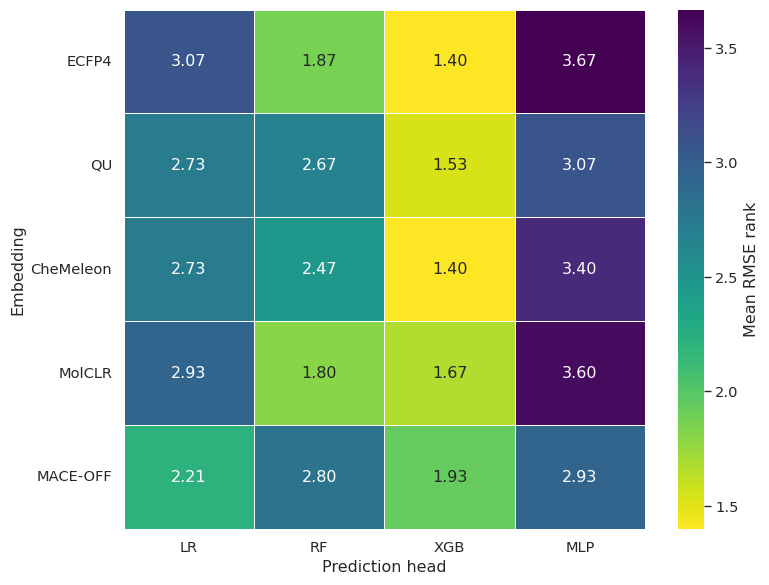

Saved 07_OUTPUTS/20260923/figures/prediction_head_mean_rmse_rank.png


In [ ]:
def plot_prediction_head_ranks(results: pd.DataFrame) -> plt.Figure:
    summary = (
        results.groupby(
            ["dataset", "embedding", "model", "split_method"],
            as_index=False,
            observed=True,
        )["test_RMSE"]
        .agg(mean_RMSE="mean")
    )
    summary["rank"] = summary.groupby(
        ["dataset", "embedding", "split_method"], observed=True
    )["mean_RMSE"].rank(method="dense", ascending=True)

    heatmap_data = (
        summary.groupby(["embedding", "model"], observed=True)["rank"]
        .mean()
        .unstack("model")
        .reindex(index=EMBEDDING_ORDER, columns=MODEL_ORDER)
    )

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".2f",
        cmap="viridis_r",
        linewidths=0.5,
        cbar_kws={"label": "Mean RMSE rank"},
        ax=ax,
    )
    ax.set(xlabel="Prediction head", ylabel="Embedding")
    ax.tick_params(axis="both", rotation=0)
    fig.tight_layout()
    save_figure(fig, "prediction_head_mean_rmse_rank.png")
    return fig


plot_prediction_head_ranks(random_results);

## Prediction parity and residuals

In [ ]:
prediction_script = REPO_ROOT / "05_PY_SCRIPTS" / "generate_xgb_predictions.py"
predictions_path = RUN_DIR / "deep_dive_xgb_predictions.parquet"
subprocess.run(
    [
        sys.executable,
        str(prediction_script),
        "--checkpoint-root",
        str(RUN_DIR),
        "--output",
        str(predictions_path),
    ],
    check=True,
)

predictions_df = pd.read_parquet(predictions_path)
predictions_df["embedding"] = predictions_df["embedding"].replace(EMBEDDING_LABELS)
predictions_df["dataset"] = predictions_df["dataset"].replace(DATASET_LABELS)
predictions_df["dataset"] = pd.Categorical(
    predictions_df["dataset"], categories=DATASET_ORDER, ordered=True
)

# Ensure the raw predictions reproduce the XGB RMSE values used above.
expected = random_results.loc[
    (random_results["model"] == "XGB")
    & random_results["embedding"].isin(["QU", "MACE-OFF"]),
    ["dataset", "embedding", "split_method", "seed", "test_RMSE"],
].copy()
expected["split_seed"] = expected["split_method"].str.extract(r"random_seed(\d+)")[0].astype(int)
expected = expected.rename(columns={"seed": "model_seed", "test_RMSE": "expected_RMSE"})
observed = (
    predictions_df.assign(squared_error=(predictions_df["y_pred"] - predictions_df["y_true"]) ** 2)
    .groupby(["dataset", "embedding", "split_seed", "model_seed"], observed=True)["squared_error"]
    .mean()
    .pow(0.5)
    .rename("observed_RMSE")
    .reset_index()
)
metric_check = expected.merge(
    observed, on=["dataset", "embedding", "split_seed", "model_seed"], how="outer", validate="one_to_one"
)
if not np.allclose(metric_check["expected_RMSE"], metric_check["observed_RMSE"], rtol=1e-5, atol=1e-6):
    raise ValueError(
        "Prediction RMSEs do not match the benchmark table; refusing to plot mismatched data.\n"
        + metric_check.loc[~np.isclose(metric_check["expected_RMSE"], metric_check["observed_RMSE"], rtol=1e-5, atol=1e-6)].to_string(index=False)
    )

predictions_df.head()

/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/xgboost/core.py:377: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc >= 2.28) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(
/home/andre/anaconda3/envs/chem/lib/python3.11/pickle.py:1718: UserWarning: [08:28:52] WARNING: /croot/xgboost-split_1749630910898/work/src/collective/../data/../common/error_msg.h:82: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that 

Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=0/ckpts/hq_descriptor_model=xgboost_seed=0.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=1/ckpts/hq_descriptor_model=xgboost_seed=1.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=2/ckpts/hq_descriptor_model=xgboost_seed=2.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=3/ckpts/hq_descriptor_model=xgboost_seed=3.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=4/ckpts/hq_descriptor_model=xgboost_seed=4.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=0/ckpts/hq_descriptor_model=xgboost_seed=0.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=1/ckpts/hq_descriptor_model=xgboost_seed=1.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=2/ckpts/hq_descriptor_model=xgboost_seed=2.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=3/ckpts/hq_descriptor_model=xgboost_seed=3.pkl
P

,dataset,embedding,split_method,split_seed,model_seed,compound_id,y_true,y_pred
0,$\rho_{cryst}$,QU,random_seed0,0,0,O=C(OCC([N+](=O)[O-])([N+](=O)[O-])[N+](=O)[O-...,1.851,1.833033
1,$\rho_{cryst}$,QU,random_seed0,0,0,O=C(CCN(CCC(=O)OCC([N+](=O)[O-])([N+](=O)[O-])...,1.703,1.706970
2,$\rho_{cryst}$,QU,random_seed0,0,0,O=[N+]([O-])c1cc([N+](=O)[O-])c(-c2c([N+](=O)[...,1.828,1.738453
3,$\rho_{cryst}$,QU,random_seed0,0,0,O=[N+]([O-])c1ccc(CC([N+](=O)[O-])([N+](=O)[O-...,1.732,1.705867
4,$\rho_{cryst}$,QU,random_seed0,0,0,Cn1nc([N+](=O)[O-])c(Nc2c([N+](=O)[O-])cc([N+]...,1.746,1.755874


In [ ]:
predictions_df

,dataset,embedding,split_method,split_seed,model_seed,compound_id,y_true,y_pred
0,$\rho_{cryst}$,QU,random_seed0,0,0,O=C(OCC([N+](=O)[O-])([N+](=O)[O-])[N+](=O)[O-...,1.851000,1.833033
1,$\rho_{cryst}$,QU,random_seed0,0,0,O=C(CCN(CCC(=O)OCC([N+](=O)[O-])([N+](=O)[O-])...,1.703000,1.706970
2,$\rho_{cryst}$,QU,random_seed0,0,0,O=[N+]([O-])c1cc([N+](=O)[O-])c(-c2c([N+](=O)[...,1.828000,1.738453
3,$\rho_{cryst}$,QU,random_seed0,0,0,O=[N+]([O-])c1ccc(CC([N+](=O)[O-])([N+](=O)[O-...,1.732000,1.705867
4,$\rho_{cryst}$,QU,random_seed0,0,0,Cn1nc([N+](=O)[O-])c(Nc2c([N+](=O)[O-])cc([N+]...,1.746000,1.755874
...,...,...,...,...,...,...,...,...
15995,IS,MACE-OFF,random_seed4,4,4,O=[N+]([O-])c1cc([N+](=O)[O-])c(C=Cc2c([N+](=O...,2.257065,2.366903
15996,IS,MACE-OFF,random_seed4,4,4,Nc1nc(N)n2nc(N)c([N+](=O)[O-])c2n1,3.688880,3.862654
15997,IS,MACE-OFF,random_seed4,4,4,Cc1c([N+](=O)[O-])cc([N+](=O)[O-])c(C)c1[N+](=...,3.199351,3.527802
15998,IS,MACE-OFF,random_seed4,4,4,Cc1c([N+](=O)[O-])c(C)c([N+](=O)[O-])c(O)c1[N+...,2.937987,3.618467


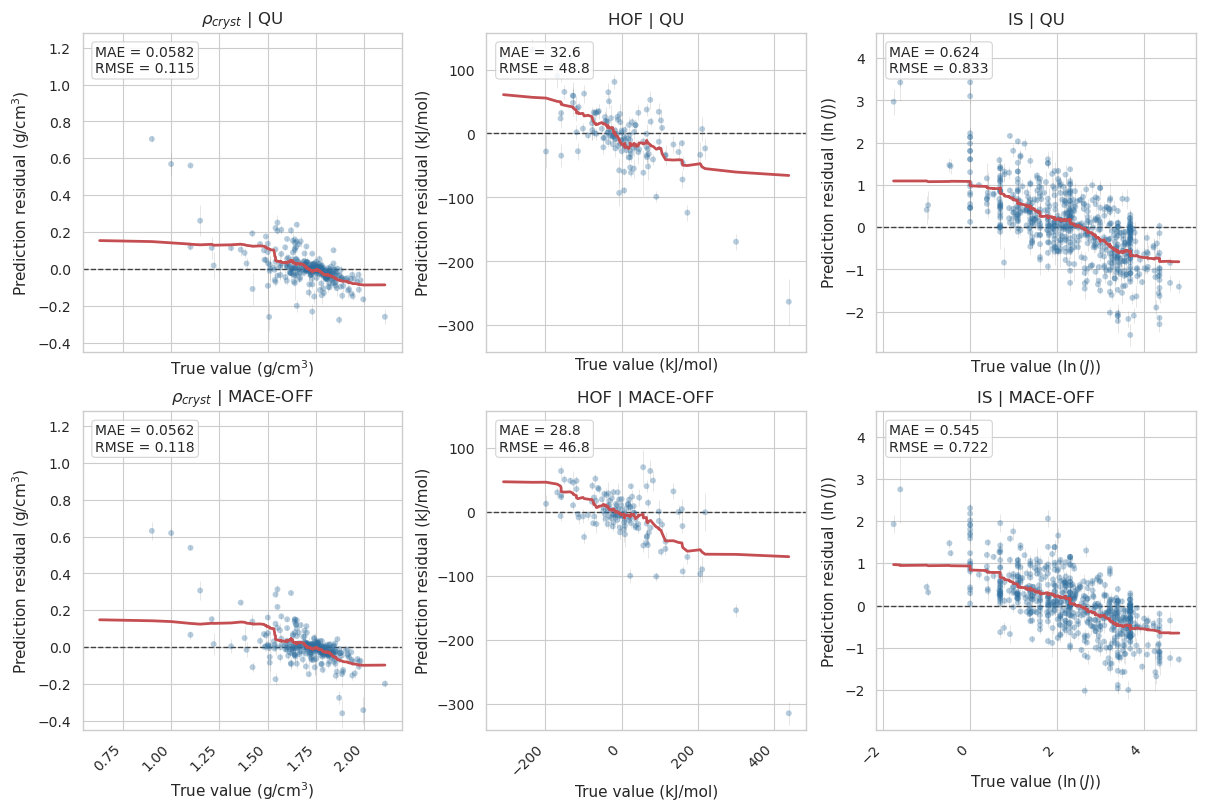

Saved 07_OUTPUTS/20260923/figures/xgb_prediction_residuals.png


In [ ]:
fig = plot_residual_grid(
    predictions_df,
    embeddings=["QU", "MACE-OFF"],
    show_pred_std=True,
    use_aggregated=True,
    figsize=(12, 8),
)
save_figure(fig, "xgb_prediction_residuals.png");

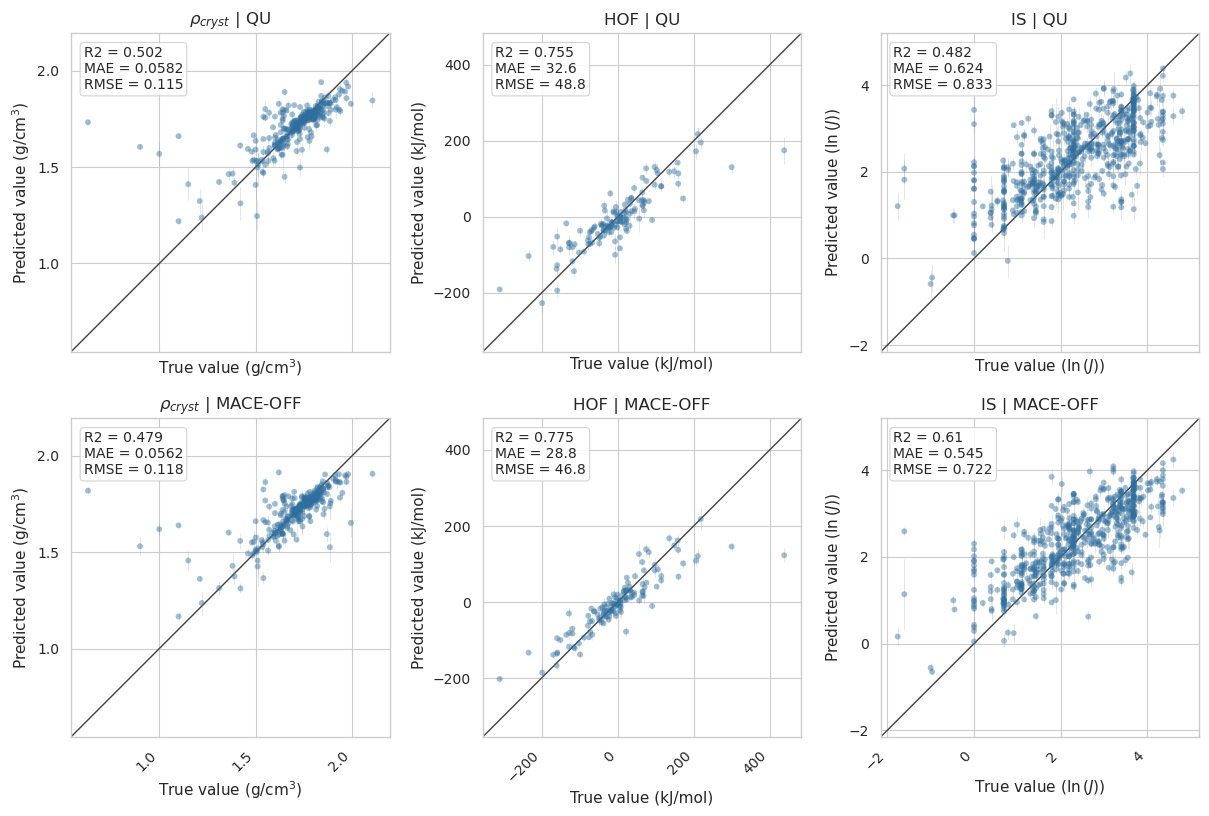

Saved 07_OUTPUTS/20260923/figures/xgb_prediction_parity.png


In [ ]:
fig = plot_parity_grid(
    predictions_df,
    embeddings=["QU", "MACE-OFF"],
    use_aggregated=True,
    color_by=None,
    show_pred_std=True,
    figsize=(12,8)
)
save_figure(fig, "xgb_prediction_parity.png");